I don't trust our signal levels at dtref in MAOS, so I'm going to check with some on-sky LBWFS images

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
from astropy.io import fits
from paarti.utils import maos_utils as mu

In [2]:
# Find all the lbwfs fits files from a given night
path = Path("/g/lu/data/kapa/2026apr29/lbwfs_images/")
fits_files = list(path.glob("*.fits.gz"))
print(fits_files)

[PosixPath('/g/lu/data/kapa/2026apr29/lbwfs_images/img3939.fits.gz'), PosixPath('/g/lu/data/kapa/2026apr29/lbwfs_images/img3998.fits.gz'), PosixPath('/g/lu/data/kapa/2026apr29/lbwfs_images/img3956.fits.gz'), PosixPath('/g/lu/data/kapa/2026apr29/lbwfs_images/img4000.fits.gz'), PosixPath('/g/lu/data/kapa/2026apr29/lbwfs_images/img3912.fits.gz'), PosixPath('/g/lu/data/kapa/2026apr29/lbwfs_images/img4009.fits.gz'), PosixPath('/g/lu/data/kapa/2026apr29/lbwfs_images/img3905.fits.gz'), PosixPath('/g/lu/data/kapa/2026apr29/lbwfs_images/img3859.fits.gz'), PosixPath('/g/lu/data/kapa/2026apr29/lbwfs_images/img3788.fits.gz'), PosixPath('/g/lu/data/kapa/2026apr29/lbwfs_images/img3865.fits.gz'), PosixPath('/g/lu/data/kapa/2026apr29/lbwfs_images/img4084.fits.gz'), PosixPath('/g/lu/data/kapa/2026apr29/lbwfs_images/img3852.fits.gz'), PosixPath('/g/lu/data/kapa/2026apr29/lbwfs_images/img4027.fits.gz'), PosixPath('/g/lu/data/kapa/2026apr29/lbwfs_images/img3875.fits.gz'), PosixPath('/g/lu/data/kapa/2026ap

In [3]:
# Pick a random image
our_file = fits_files[100]
print(our_file)
img = fits.open(our_file)

/g/lu/data/kapa/2026apr29/lbwfs_images/img4052.fits.gz


AOLBSVDR='/nightly/tonight/Lbwfs/' / save directory                              [astropy.io.fits.card]
AOFCLBFO=0.0057114360463842405 / m                                               [astropy.io.fits.card]


In [4]:
# Get the header and the image data
hdr = img[0].header
data = img[0].data

In [5]:
print(hdr["AOLBTTME"], "second integration") # Integration time in seconds
print(hdr["LGTTRMAG"], "R mag tip tilt star") # Tip tilt star R magnitude
print(hdr["TARGVMAG"], "V mag target") # Target V magnitude?

tt_star_R_mag = hdr["LGTTRMAG"]
integration_time = hdr["AOLBTTME"]

10.0 second integration
13.87 R mag tip tilt star
14.0 V mag target


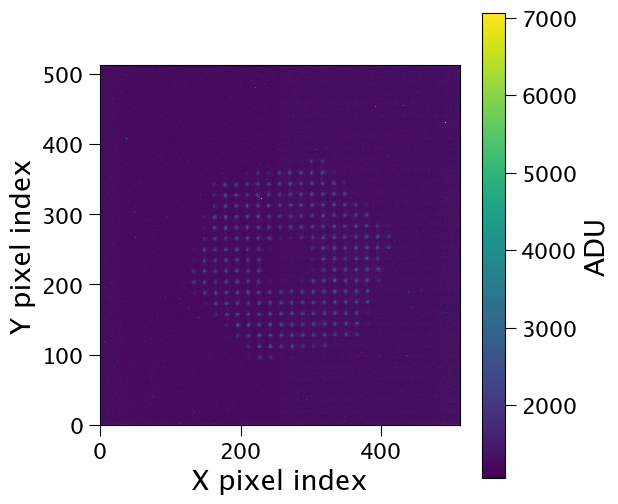

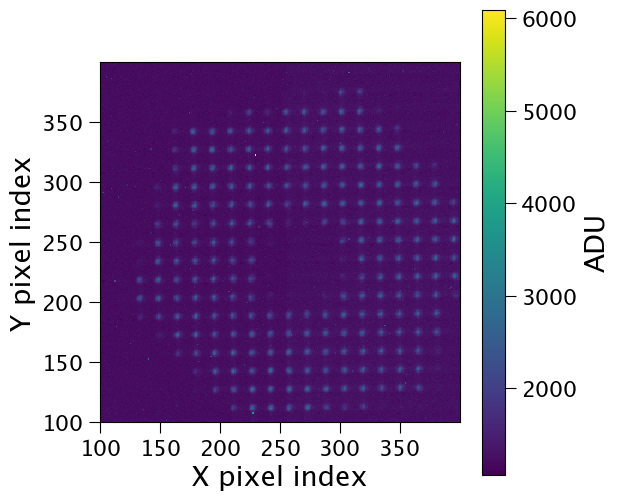

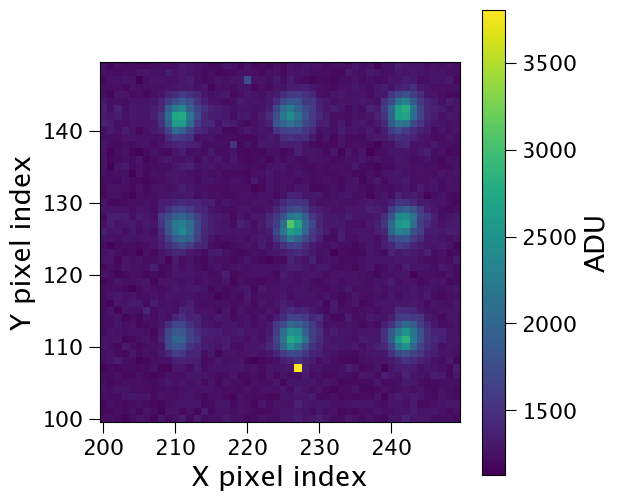

In [6]:
# Allegedly the image is made of 20x20 subaps which are 15.4 pixels each. Let's look at the data and verify that
# Show the whole image
plt.imshow(data, origin="lower", cmap="viridis")
plt.xlabel("X pixel index")
plt.ylabel("Y pixel index")
plt.colorbar(label="ADU")
plt.show()

# Zoom in on the central 100-400x100-400 pixels. Make sure the x and y ticks match up with the 
# data being shown (ie 100-400 not 0-300)
left_lim = 100
right_lim = 400
bottom_lim = 100
top_lim = 400
plt.imshow(data[bottom_lim:top_lim, left_lim:right_lim], origin="lower", cmap="viridis")
plt.xlabel("X pixel index")
plt.ylabel("Y pixel index")
plt.colorbar(label="ADU")
steps = 50
plt.xticks(np.arange(0, right_lim-left_lim, steps), np.arange(left_lim, right_lim, steps).astype(int))
plt.yticks(np.arange(0, top_lim-bottom_lim, steps), np.arange(bottom_lim, top_lim, steps).astype(int))
plt.show()

# Same as above but we're zooming in on a smaller region, 200-250 x 100-150 pixels
left_lim = 200
right_lim = 250
bottom_lim = 100
top_lim = 150
plt.imshow(data[bottom_lim:top_lim, left_lim:right_lim], origin="lower", cmap="viridis")
plt.xlabel("X pixel index")
plt.ylabel("Y pixel index")
plt.colorbar(label="ADU")
steps = 10
plt.xticks(np.arange(0, right_lim-left_lim, steps), np.arange(left_lim, right_lim, steps).astype(int))
plt.yticks(np.arange(0, top_lim-bottom_lim, steps), np.arange(bottom_lim, top_lim, steps).astype(int))
plt.show()

In [7]:
r0 = 0.14
mu.keck_nea_photons(tt_star_R_mag, "LBWFS", r0, wfs_int_time=integration_time)

Assumptions:
  Wave-Front Sensor       = LBWFS
  Pupil Aperture Diameter = 0.56 m (assumed square)
  Throughput (w QE)       = 0.03
  Plate Scale             = 0.148 arcsec/pix
  Spot Size Diameter      = 1.049 arcsec
  Filter                  = R
  Readnoise               = 7.96 e-
  Pixels per Subaperture  = 278.89
  Integration Time        = 10.0000 s
  Guide Star Magnitude    = 13.87

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 2797.342
  N_photons per pixel from background (powfs.bkgrnd): 0.164
  SNR: 19.531
  NEA (powfs.nearecon): 53.687 mas


(19.530797555459316,
 53.687294283150884,
 2797.3421801719737,
 0.16416063552750437)

In [82]:
subap_side_length = 0.563 # meters
pixel_scale = 0.148 # arcsec/pixel
throughput = 0.03
integration_time = 10 # seconds
Np, Nb = mu.n_photons(subap_side_length, integration_time, tt_star_R_mag, "R", pixel_scale, throughput)
print(Np, f"photons per subap per frame at {integration_time}s integration time")
print(Nb, f"background photons per pixel per frame at {integration_time}s integration time")

2797.3421801719737 photons per subap per frame at 10s integration time
0.16416063552750437 background photons per pixel per frame at 10s integration time


In [83]:
integration_time = 1 # seconds
Np, Nb = mu.n_photons(subap_side_length, integration_time, tt_star_R_mag, "R", pixel_scale, throughput)
print(Np, f"photons per subap per frame at {integration_time}s integration time")
print(Nb, f"background photons per pixel per frame at {integration_time}s integration time")

279.7342180171974 photons per subap per frame at 1s integration time
0.016416063552750437 background photons per pixel per frame at 1s integration time


In [84]:
integration_time = 1/472 # seconds
Np, Nb = mu.n_photons(subap_side_length, integration_time, tt_star_R_mag, "R", pixel_scale, throughput)
print(Np, f"photons per subap per frame at {integration_time}s integration time")
print(Nb, f"background photons per pixel per frame at {integration_time}s integration time")

0.5926572415618588 photons per subap per frame at 0.00211864406779661s integration time
3.477979566260685e-05 background photons per pixel per frame at 0.00211864406779661s integration time


In [9]:
pix_per_ap = 16 * 16 # Pixels per subaperture
read_noise = 7.96
SNR = Np / np.sqrt(Np + pix_per_ap*Nb + pix_per_ap*read_noise**2)
print(SNR, "SNR per subap per frame at 10s integration time")

20.26211914073301 SNR per subap per frame at 10s integration time


In [10]:
# So here we'd expect num_electrons/subap = 2797 electrons + .164 electrons/pixel * 256 pixels + 7.96^2 electrons/pixel * 256 pixels
# We square the read noise because the variance of the RN is equal to the mean of the RN, but 7.96 is the std dev which is the square root of the variance
# So var = 7.96^2, and we multiply by the number of pixels to get the total variance from the read noise across the subaperture
total_electrons_per_subap = Np + pix_per_ap*Nb + pix_per_ap * (read_noise**2)
print(total_electrons_per_subap, "total electrons per subaperture at 10s integration time")

# If we think we'll subtract off the read noise when we subtract the bias, then we'd have
total_electrons_per_subap_min = Np + pix_per_ap * Nb
print(total_electrons_per_subap_min, "total electrons per subaperture at 10s integration time (minus read noise)")

19059.936902867015 total electrons per subaperture at 10s integration time
2839.367302867015 total electrons per subaperture at 10s integration time (minus read noise)


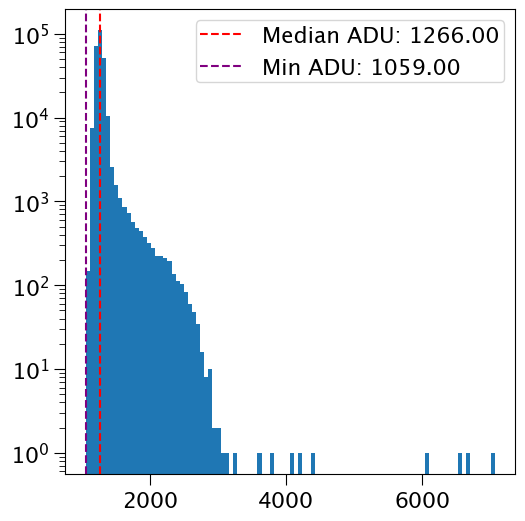

In [11]:
# Let's bias subtract based on values in the image
bottom_lim = 0
top_lim = 3000
plt.hist(data.flatten(), bins=100)
plt.axvline(np.median(data.flatten()), color="red", label=f"Median ADU: {np.median(data.flatten()):.2f}", linestyle='--')
plt.axvline(data.flatten().min(), color='purple', label=f"Min ADU: {data.flatten().min():.2f}", linestyle='--')
# plt.xlim(bottom_lim, top_lim)
plt.yscale('log')
plt.legend()
plt.show()

In [12]:
# # Let's be conservative and say the bias level is 1059 ADU, which is the minimum pixel value
# bias_level = 1059
# data_bias_subtracted = data - bias_level

# We'll say the bias level is actually the median, 1266 ADU
bias_level = np.median(data.flatten())
data_bias_subtracted = data - bias_level

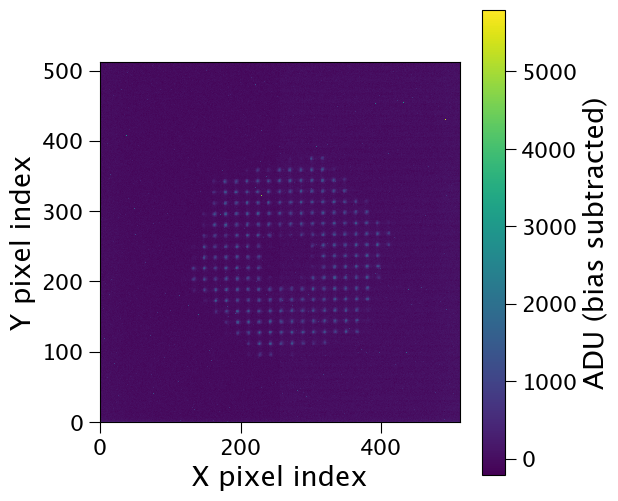

In [13]:
plt.imshow(data_bias_subtracted, origin="lower", cmap="viridis")
plt.xlabel("X pixel index")
plt.ylabel("Y pixel index")
plt.colorbar(label="ADU (bias subtracted)")
plt.show()

In [14]:
# Any data below 0 will be brought up to 0
data_bias_subtracted_lower_clipped = np.clip(data_bias_subtracted, a_min=0, a_max=None)

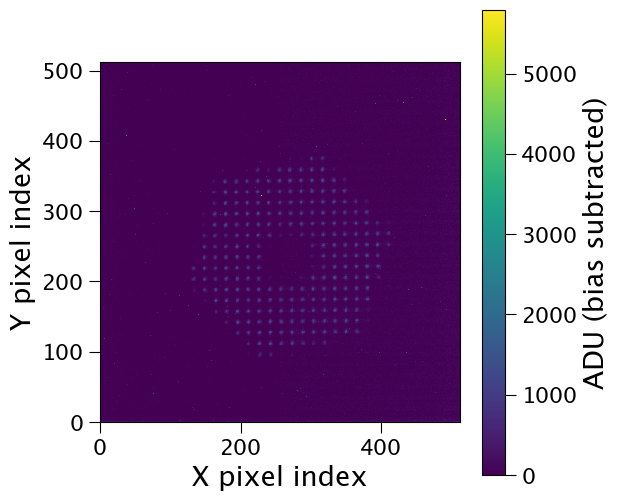

In [15]:
plt.imshow(data_bias_subtracted_lower_clipped, origin="lower", cmap="viridis")
plt.xlabel("X pixel index")
plt.ylabel("Y pixel index")
plt.colorbar(label="ADU (bias subtracted)")
plt.show()

In [16]:
# Let's also clip the data to be a max of 3250 ADU to get rid of hot pixels
# print(f"Max ADU before clipping: {data_bias_subtracted.max()}")
# print(f"Min ADU before clipping: {data_bias_subtracted.min()}")
# data_bias_subtracted_clipped = np.clip(data_bias_subtracted, None, 3250)
# print(f"Max ADU after clipping: {data_bias_subtracted_clipped.max()}")
# print(f"Min ADU after clipping: {data_bias_subtracted_clipped.min()}")

# Just kidding, we're going to set the hot pixels to be 0. ANything over thresh gets set to 0
thresh = 2100
data_bias_subtracted_clipped = np.where(data_bias_subtracted_lower_clipped > thresh, 0, data_bias_subtracted_lower_clipped)
print(f"Max ADU after clipping: {data_bias_subtracted_clipped.max()}")
print(f"Min ADU after clipping: {data_bias_subtracted_clipped.min()}")

Max ADU after clipping: 1962.0
Min ADU after clipping: 0.0


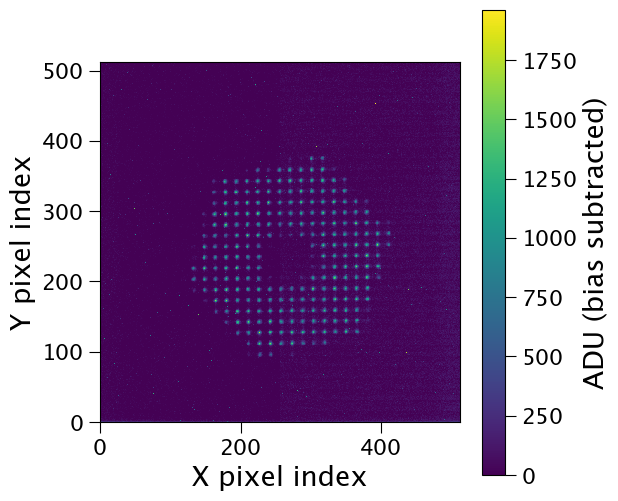

In [17]:
plt.imshow(data_bias_subtracted_clipped, origin="lower", cmap="viridis")
plt.xlabel("X pixel index")
plt.ylabel("Y pixel index")
plt.colorbar(label="ADU (bias subtracted)")
plt.show()

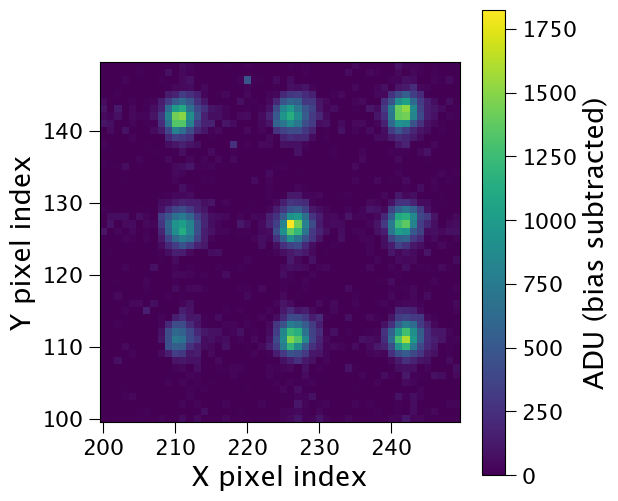

In [18]:
# Plot the bias subtracted LBWFS image in our smallest region
left_lim = 200
right_lim = 250
bottom_lim = 100
top_lim = 150
plt.imshow(data_bias_subtracted_clipped[bottom_lim:top_lim, left_lim:right_lim], origin="lower", cmap="viridis")
plt.xlabel("X pixel index")
plt.ylabel("Y pixel index")
plt.xticks(np.arange(0, right_lim-left_lim, steps), np.arange(left_lim, right_lim, steps).astype(int))
plt.yticks(np.arange(0, top_lim-bottom_lim, steps), np.arange(bottom_lim, top_lim, steps).astype(int))
plt.colorbar(label="ADU (bias subtracted)")
plt.show()

In [19]:
# Let's subtend the bias subtracted image into 16x16 pixel subapertures
# To do this, we'll fit a grid of 20x20 2d Gaussians to the image masked by the subap_map
# Then once we have the centers of the Gaussians, the separation between them, and the angle they're rotated,
# we can use that to determine which pixels belong to which subaps by drawing a grid over the image with the same
# parameters as the grid of fitted gaussians and whichever box a pixel falls into is the subap it belongs to

In [20]:
import reflectao.telemetry_utils as tu
subap_map = tu.load_subap_map()
print(subap_map.shape)

(20, 20)


In [33]:
# GEMINI GENERATED CODE TO DO THIS
import numpy as np
from scipy.optimize import least_squares

def generate_sh_grid_masked(params, X, Y, subap_map):
    """
    Generates the sensor image using only the lit subapertures.
    """
    x0, y0, k, theta_deg, sigma = params
    theta = np.radians(theta_deg)

    A = 1400.0  # Amplitude of the Gaussian spots (can be adjusted based on expected brightness)
    
    # Extract the row (J) and column (I) indices where the map is NOT nan
    # J corresponds to the y-direction (rows), I corresponds to the x-direction (cols)
    J_valid, I_valid = np.where(~np.isnan(subap_map))
    
    # Calculate centroids ONLY for the 304 lit spots
    xc = x0 + k * (I_valid * np.cos(theta) - J_valid * np.sin(theta))
    yc = y0 + k * (I_valid * np.sin(theta) + J_valid * np.cos(theta))
    
    # Vectorization setup for the remaining spots
    X_ext = X[:, :, np.newaxis]
    Y_ext = Y[:, :, np.newaxis]
    xc_ext = xc[np.newaxis, np.newaxis, :]
    yc_ext = yc[np.newaxis, np.newaxis, :]
    
    denom = 2.0 * sigma**2
    
    # Calculate and sum the 304 Gaussians simultaneously
    Z = np.sum(A * np.exp(-((X_ext - xc_ext)**2 + (Y_ext - yc_ext)**2) / denom), axis=2)
    
    return Z

def residuals_masked(params, X, Y, data, subap_map):
    """ Residuals function passing the subap_map. """
    model = generate_sh_grid_masked(params, X, Y, subap_map)
    return (data - model).ravel()

def fit_shack_hartmann_grid_masked(data_bias_subtracted, subap_map):
    y_coords, x_coords = np.mgrid[0:512, 0:512]
    
    # Initial Guesses
    x0_guess = 120 + 16 * 0 - 4
    y0_guess = 80 + 16 * 0 + 4
    k_guess = 15.4    
    theta_guess = 1
    sigma_guess = 1.5  # Reasonable starting width for spots 16px apart
    # A_guess = 1500.0   # Middle of your 0-3000 ADU range
    # p0 = [x0_guess, y0_guess, k_guess, theta_guess, sigma_guess, A_guess]
    p0 = [x0_guess, y0_guess, k_guess, theta_guess, sigma_guess]
    
    # Parameter Bounds
    # lower_bounds = [50.0, 50.0, 14, 0, 1, 1000.0]
    # upper_bounds = [175.0, 100.0, 18, 5, 3, 2000.0]
    lower_bounds = [50.0, 50.0, 14, 0, 1]
    upper_bounds = [175.0, 100.0, 18, 5, 3]
    
    print("Starting masked optimization...")
    
    res = least_squares(
        residuals_masked, 
        p0, 
        bounds=(lower_bounds, upper_bounds),
        args=(x_coords, y_coords, data_bias_subtracted, subap_map),
        method='trf', 
        ftol=1e-3, 
        xtol=1e-3, 
        max_nfev=40 # Hard stop to prevent the optimizer from hanging
    )
    
    if res.success:
        print("Fit converged!")
    else:
        print(f"Fit stopped: {res.message}")
        
    # x_fit, y_fit, k_fit, theta_fit, sigma_fit, A_fit = res.x
    x_fit, y_fit, k_fit, theta_fit, sigma_fit = res.x
    
    # return x_fit, y_fit, k_fit, theta_fit, sigma_fit, A_fit 
    return x_fit, y_fit, k_fit, theta_fit, sigma_fit


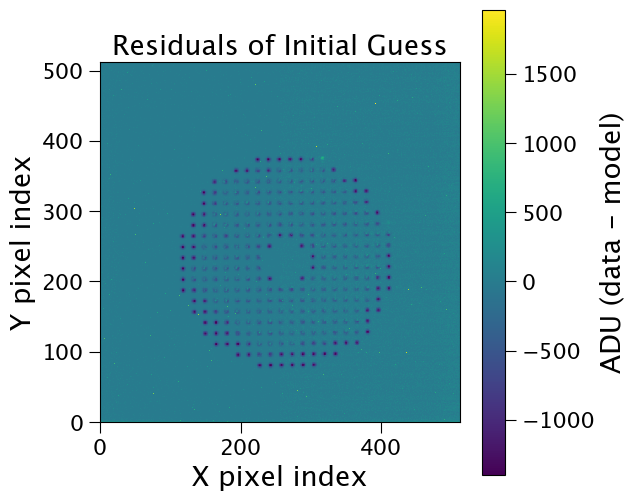

In [58]:
# 2. Initial Guesses
# Bottom left pixel roughly around (100, 100) based on your bounding box
x0_guess = 120 + 16 * 0 - 1
y0_guess = 80 + 16 * 0 - 1
k_guess = 15.4    
theta_guess = .6
sigma_guess = 2  # Reasonable starting width for spots 16px apart
# A_guess = 1500.0   # Middle of your 0-3000 ADU range

# p0 = [x0_guess, y0_guess, k_guess, theta_guess, sigma_guess, A_guess]
p0 = [x0_guess, y0_guess, k_guess, theta_guess, sigma_guess]

params = p0
y_coords, x_coords = np.mgrid[0:512, 0:512]
Z = generate_sh_grid_masked(params, x_coords, y_coords, subap_map)

# # Visualize guesses 
# plt.imshow(Z, origin="lower", cmap="viridis")
# plt.xlabel("X pixel index")
# plt.ylabel("Y pixel index")
# plt.colorbar(label="ADU (model)")
# plt.title("Initial Guess Shack-Hartmann Grid Model")
# plt.show()

# Visualize residuals
residual_image = data_bias_subtracted_clipped - Z
plt.imshow(residual_image, origin="lower", cmap="viridis")
plt.xlabel("X pixel index")
plt.ylabel("Y pixel index")
plt.colorbar(label="ADU (data - model)")
plt.title("Residuals of Initial Guess")
plt.show()

In [36]:
# x_fit, y_fit, k_fit, theta_fit, sigma_fit, A_fit = fit_shack_hartmann_grid_masked(data_bias_subtracted_clipped, subap_map)
x_fit, y_fit, k_fit, theta_fit, sigma_fit = fit_shack_hartmann_grid_masked(data_bias_subtracted_clipped, subap_map)

Starting masked optimization...
Fit converged!


In [40]:
# print(x_fit, y_fit, k_fit, theta_fit, sigma_fit, A_fit)
print("fit:", x_fit, y_fit, k_fit, theta_fit, sigma_fit)
print("Guesses:", p0)

fit: 116.05415071136343 83.93604329021696 15.401319571629132 1.0025486594486672 1.0057692393895805
Guesses: [116, 84, 15.4, 1, 1.5]


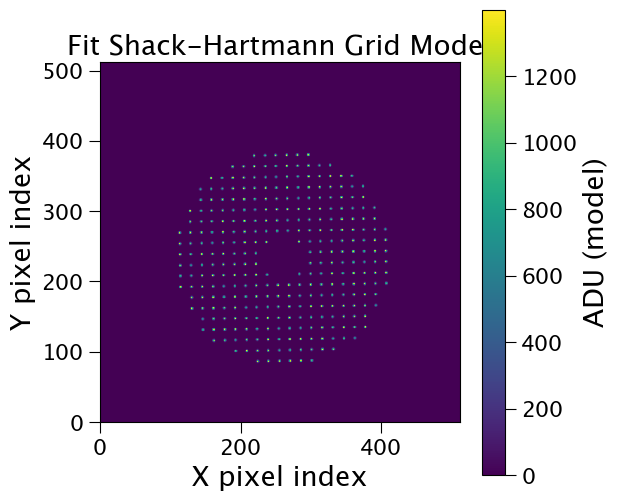

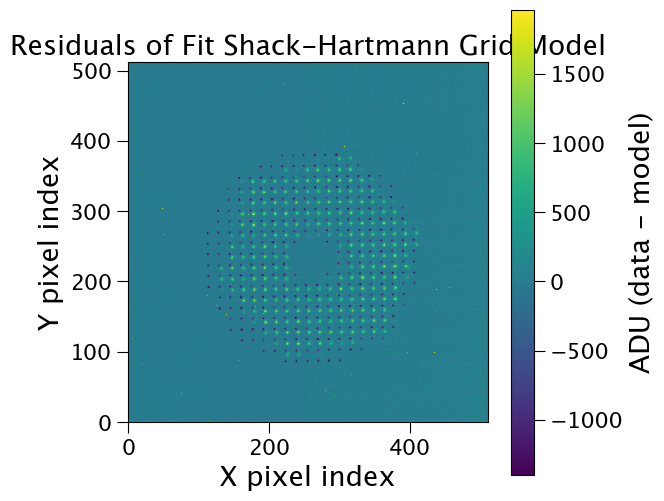

In [41]:
# params = [x_fit, y_fit, k_fit, theta_fit, sigma_fit, A_fit]
params = [x_fit, y_fit, k_fit, theta_fit, sigma_fit]
y_coords, x_coords = np.mgrid[0:512, 0:512]
Z = generate_sh_grid_masked(params, x_coords, y_coords, subap_map)

# Visualize guesses 
plt.imshow(Z, origin="lower", cmap="viridis")
plt.xlabel("X pixel index")
plt.ylabel("Y pixel index")
plt.colorbar(label="ADU (model)")
plt.title("Fit Shack-Hartmann Grid Model")
plt.show()

# Visualize residuals
residual_image = data_bias_subtracted_clipped - Z
plt.imshow(residual_image, origin="lower", cmap="viridis")
plt.xlabel("X pixel index")
plt.ylabel("Y pixel index")
plt.colorbar(label="ADU (data - model)")
plt.title("Residuals of Fit Shack-Hartmann Grid Model")
plt.show()

In [59]:
print(p0_coarse)

[119, 79, 15.4, 0.6, 1.5]


In [60]:
from scipy.ndimage import gaussian_filter

# ---------------------------------------------------------
# STAGE 1: THE BLURRY COARSE FIT
# ---------------------------------------------------------
print("--- STAGE 1: Coarse Fit on Blurred Data ---")

# 1. Blur the data heavily (sigma=4 means spreading the spots by ~10 pixels)
blur_radius = 4.0
data_blurred = gaussian_filter(data_bias_subtracted_clipped, sigma=blur_radius)

# 2. Initial guesses (using your previous closest guess)
p0_coarse = [x0_guess, y0_guess, k_guess, theta_guess, sigma_guess]

# 3. Widened bounds (allow sigma to get massive, allow amplitude to float)
lower_bounds_coarse = [50.0, 50.0, 14.0, 0, 2.0]
upper_bounds_coarse = [175.0, 100.0, 18.0, 1, 10.0]

res_coarse = least_squares(
    residuals_masked, 
    p0_coarse, 
    bounds=(lower_bounds_coarse, upper_bounds_coarse),
    args=(x_coords, y_coords, data_blurred, subap_map),
    method='trf', 
    ftol=1e-3, 
    xtol=1e-3, 
    max_nfev=60 
)

x_c, y_c, k_c, theta_c, sigma_c = res_coarse.x
print(f"Coarse Results:\n x={x_c:.2f}, y={y_c:.2f}, k={k_c:.2f}, theta={theta_c:.2f}, sigma={sigma_c:.2f}")

# ---------------------------------------------------------
# STAGE 2: THE SHARP FINE FIT
# ---------------------------------------------------------
print("\n--- STAGE 2: Fine Fit on Original Data ---")

# 1. Use the coarse coordinates, but reset sigma and A to realistic sharp values
p0_fine = [x_c, y_c, k_c, theta_c, 1.5] # Note: No more A parameter

# 2. Tight bounds (lock the coordinates so they don't wander far, allow tight sigma)
lower_bounds_fine = [x_c - 2.0, y_c - 2.0, k_c - 0.5, theta_c - 0.5, 0.5]
upper_bounds_fine = [x_c + 2.0, y_c + 2.0, k_c + 0.5, theta_c + 0.5, 3.0]

res_fine = least_squares(
    residuals_masked, 
    p0_fine, 
    bounds=(lower_bounds_fine, upper_bounds_fine),
    args=(x_coords, y_coords, data_bias_subtracted_clipped, subap_map), # USING ORIGINAL DATA
    method='trf', 
    ftol=1e-4, # Tighter tolerance for the final lock
    xtol=1e-4, 
    max_nfev=60 
)

x_f, y_f, k_f, theta_f, sigma_f = res_fine.x
print(f"Fine Results:\n x={x_f:.2f}, y={y_f:.2f}, k={k_f:.2f}, theta={theta_f:.2f}, sigma={sigma_f:.2f}")

# Generate final model for plotting
final_params = [x_f, y_f, k_f, theta_f, sigma_f]
Z_final = generate_sh_grid_masked(final_params, x_coords, y_coords, subap_map)

--- STAGE 1: Coarse Fit on Blurred Data ---
Coarse Results:
 x=119.01, y=79.01, k=15.40, theta=0.61, sigma=2.00

--- STAGE 2: Fine Fit on Original Data ---
Fine Results:
 x=119.00, y=79.03, k=15.41, theta=0.69, sigma=1.31


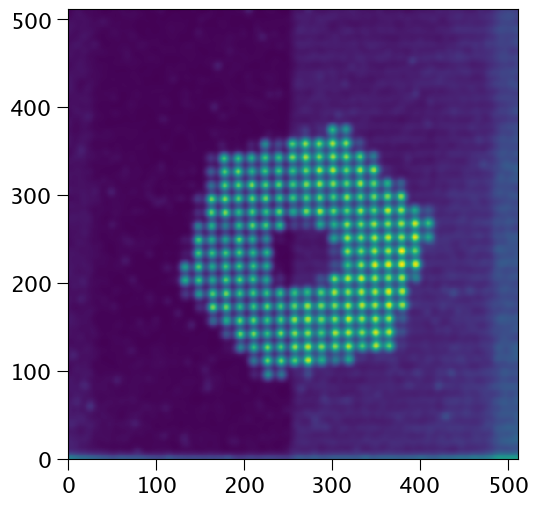

In [61]:
plt.imshow(data_blurred, origin="lower", cmap="viridis")

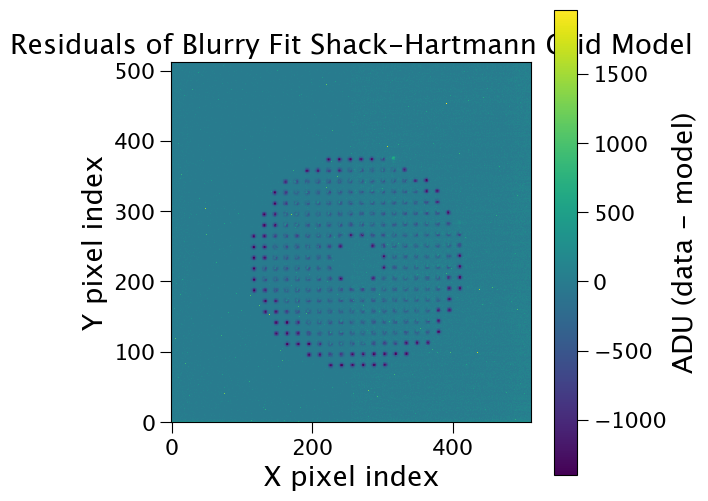

In [62]:
# Visualize residuals
x=119.01
y=79.01
k=15.40
theta=0.61
sigma=2.00
Z = generate_sh_grid_masked([x, y, k, theta, sigma], x_coords, y_coords, subap_map)
residual_image = data_bias_subtracted_clipped - Z
plt.imshow(residual_image, origin="lower", cmap="viridis")
plt.xlabel("X pixel index")
plt.ylabel("Y pixel index")
plt.colorbar(label="ADU (data - model)")
plt.title("Residuals of Blurry Fit Shack-Hartmann Grid Model")
plt.show()

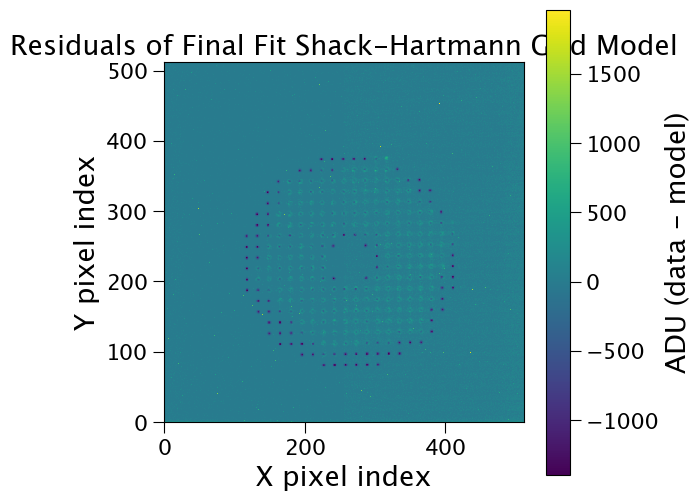

In [63]:
# Visualize residuals
residual_image = data_bias_subtracted_clipped - Z_final
plt.imshow(residual_image, origin="lower", cmap="viridis")
plt.xlabel("X pixel index")
plt.ylabel("Y pixel index")
plt.colorbar(label="ADU (data - model)")
plt.title("Residuals of Final Fit Shack-Hartmann Grid Model")
plt.show()

In [64]:
#  x=119.00, y=79.03, k=15.41, theta=0.69, sigma=1.31 is a good fit!



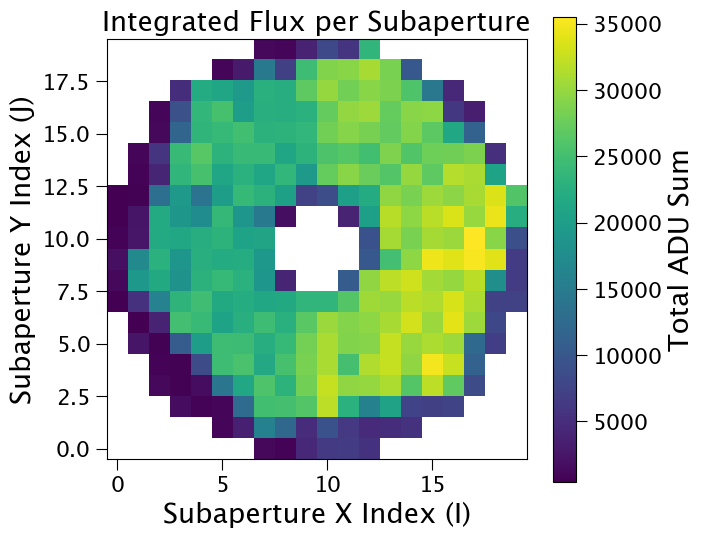

In [67]:
# Gemini generated code
def integrate_subaperture_flux(data, subap_map, params_fit):
    """
    Assigns pixels to their corresponding tilted square subapertures and sums the ADUs.
    params_fit: [x0, y0, k, theta_deg, sigma, A]
    """
    # Unpack the geometric parameters (we don't need sigma or A here)
    x0, y0, k, theta_deg, *_ = params_fit
    theta = np.radians(theta_deg)
    
    # 1. Create the detector pixel coordinate grid
    Y, X = np.mgrid[0:data.shape[0], 0:data.shape[1]]
    
    # 2. Shift to origin
    X_shifted = X - x0
    Y_shifted = Y - y0
    
    # 3. Apply the inverse rotation and scale to index space
    # The inverse rotation matrix swaps the signs on the sine terms
    I_float = ( X_shifted * np.cos(theta) + Y_shifted * np.sin(theta)) / k
    J_float = (-X_shifted * np.sin(theta) + Y_shifted * np.cos(theta)) / k
    
    # 4. Round to nearest integer to assign pixels to subaperture bins
    I_idx = np.round(I_float).astype(int)
    J_idx = np.round(J_float).astype(int)
    
    # Initialize an output array filled with NaNs for the sums
    flux_sums = np.full_like(subap_map, np.nan)
    
    # Extract the valid indices from your mask
    J_valid, I_valid = np.where(~np.isnan(subap_map))
    
    # 5. Integrate flux for each valid subaperture
    for j, i in zip(J_valid, I_valid):
        # Create a boolean mask of all pixels that map to this specific (i, j) subaperture
        pixel_mask = (I_idx == i) & (J_idx == j)
        
        # Sum the actual data values where the mask is True
        flux_sums[j, i] = np.sum(data[pixel_mask])
        
    return flux_sums

# ==========================================
# Example Usage and Visualization
# ==========================================
# Make sure your final params are in the right order from the fine fit:
# final_params = [x_f, y_f, k_f, theta_f, sigma_f, A_f]

integrated_flux = integrate_subaperture_flux(data_bias_subtracted_clipped, subap_map, final_params)

# Visualize the resulting summed array
plt.figure(figsize=(7, 6))
# Using origin='lower' to match the orientation of your detector
plt.imshow(integrated_flux, origin='lower', cmap='viridis')
plt.colorbar(label='Total ADU Sum')
plt.title('Integrated Flux per Subaperture')
plt.xlabel('Subaperture X Index (I)')
plt.ylabel('Subaperture Y Index (J)')
plt.show()

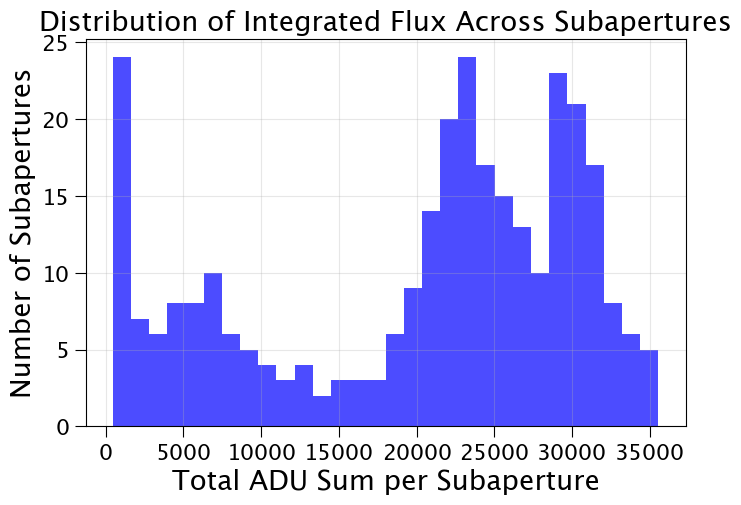

In [68]:
# Histogram the subaperture intensities
plt.figure(figsize=(8, 5))
plt.hist(integrated_flux[~np.isnan(integrated_flux)].flatten(), bins=30, color='blue', alpha=0.7)
plt.xlabel('Total ADU Sum per Subaperture')
plt.ylabel('Number of Subapertures')
plt.title('Distribution of Integrated Flux Across Subapertures')
plt.grid(True, alpha=0.3)
plt.show()

Peak 1 Median: 23161.00 ADU (Count: 119)
Peak 2 Median: 30240.00 ADU (Count: 89)


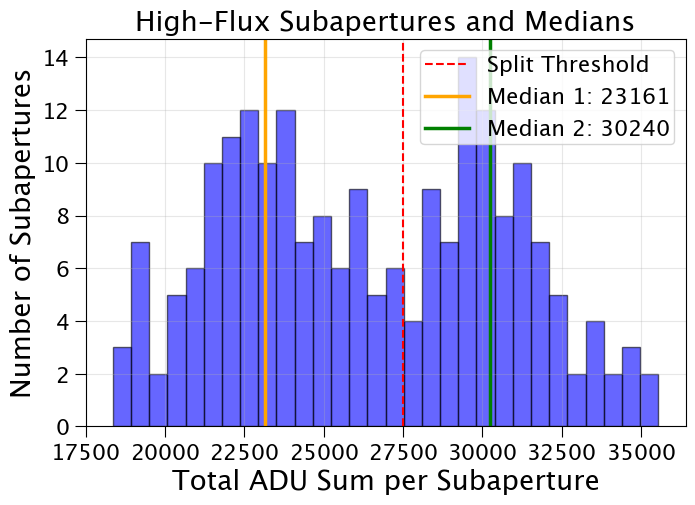

In [74]:
# 1. Filter out NaNs and the dead/zero-flux subapertures
valid_flux = integrated_flux[~np.isnan(integrated_flux)]
high_flux = valid_flux[valid_flux > 18000]

# 2. Define the valley threshold to split the two peaks
# (Adjust this if your histogram valley sits somewhere else)
split_threshold = 27500

# 3. Mask the data into the two distinct populations
peak_1_data = high_flux[high_flux < split_threshold]
peak_2_data = high_flux[high_flux >= split_threshold]

# 4. Calculate the true statistical medians of the raw arrays
median_1 = np.median(peak_1_data)
median_2 = np.median(peak_2_data)

print(f"Peak 1 Median: {median_1:.2f} ADU (Count: {len(peak_1_data)})")
print(f"Peak 2 Median: {median_2:.2f} ADU (Count: {len(peak_2_data)})")

# ==========================================
# Visualize the Split and the Medians
# ==========================================
plt.figure(figsize=(8, 5))
# Plot just the high_flux data so we can see the two peaks clearly
plt.hist(high_flux, bins=30, color='blue', alpha=0.6, edgecolor='black')

# Plot the threshold line
plt.axvline(split_threshold, color='red', linestyle='--', linewidth=1.5, label='Split Threshold')

# Plot the medians
plt.axvline(median_1, color='orange', linestyle='-', linewidth=2.5, label=f'Median 1: {median_1:.0f}')
plt.axvline(median_2, color='green', linestyle='-', linewidth=2.5, label=f'Median 2: {median_2:.0f}')

plt.xlabel('Total ADU Sum per Subaperture')
plt.ylabel('Number of Subapertures')
plt.title('High-Flux Subapertures and Medians')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [78]:
# Get a gain from expected e- & measured ADU per subap
avg_count_per_subap = np.mean([median_1, median_2])
print(avg_count_per_subap, "ADU per subaperture (average of medians)")
print(total_electrons_per_subap_min, "Expected electrons per subap (with read noise taken out by the bias subtraction)")
print(avg_count_per_subap / total_electrons_per_subap_min, "Gain in ADU/electron")

26700.5 ADU per subaperture (average of medians)
2839.367302867015 Expected electrons per subap (with read noise taken out by the bias subtraction)
9.403679465153912 Gain in ADU/electron


In [ ]:
# Check KAON 265 & 1358
# 1358 says 4 e- / ADU on keck II
# Gains set to 30, 10, 3, and 1 are listed on the K1 LBWFS data sheet
# Gain of 30 for the 3.448Hz program, gain of 10 for the 1056x program, and gain of 3 for hte 1024 program

In [80]:
# Estimated signal in e-/subap/frame at 10s exposure time using these gains
# gain = ADU / e- so e- = ADU / gain
print("Gain of 1:", avg_count_per_subap / 1, "e- per subaperture at 10s integration time")
print("Gain of 3:", avg_count_per_subap / 3, "e- per subaperture at 10s integration time")
print("Gain of 10:", avg_count_per_subap / 10, "e- per subaperture at 10s integration time")
print("Gain of 30:", avg_count_per_subap / 30, "e- per subaperture at 10s integration time")

Gain of 1: 26700.5 e- per subaperture at 10s integration time
Gain of 3: 8900.166666666666 e- per subaperture at 10s integration time
Gain of 10: 2670.05 e- per subaperture at 10s integration time
Gain of 30: 890.0166666666667 e- per subaperture at 10s integration time
